<a href="https://colab.research.google.com/github/Ossel14/atelier1-deeplearning/blob/main/Atelier2_part2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atelier 1 — Deep Learning avec PyTorch

## Partie 2 : Classification multiclasses

### Objectif

Construire un réseau de neurones profond (MLP) capable de
prédire le type de panne d'une machine industrielle.

Le travail comprend :
- Prétraitement et nettoyage des données
- Analyse exploratoire (EDA)
- Équilibrage des classes
- Classification multiclasses avec PyTorch
- Optimisation des hyperparamètres avec GridSearchCV
- Évaluation et régularisation du modèle

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from pathlib import Path

# Reproductibilité
np.random.seed(42)
torch.manual_seed(42)

# Vérification de l'environnement
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version :", torch.__version__)
print("Device utilisé :", device)

PyTorch version : 2.11.0+cu130
Device utilisé : cuda


In [ ]:
import kagglehub

# Télécharger le dataset Kaggle
dataset_path = kagglehub.dataset_download(
    "shivamb/machine-predictive-maintenance-classification"
)

# Localiser le fichier CSV
csv_files = list(Path(dataset_path).glob("*.csv"))

print("Fichiers CSV disponibles :")
print([p.name for p in csv_files])

# Charger le dataset
file_path = next(
    p for p in csv_files
    if p.name == "predictive_maintenance.csv"
)

df = pd.read_csv(file_path)

print("\nDimensions du dataset :", df.shape)
print("\nColonnes :", df.columns.tolist())

display(df.head())

100%|██████████| 137k/137k [00:00<00:00, 32.0MB/s]

Extracting files...
Fichiers CSV disponibles :
['predictive_maintenance.csv']

Dimensions du dataset : (10000, 10)

Colonnes : ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [ ]:
print("Types de pannes :")
print(df["Failure Type"].unique())

print("\nNombre de classes :")
print(df["Failure Type"].nunique())

print("\nRépartition des observations par classe :")
display(df["Failure Type"].value_counts())

Types de pannes :
['No Failure' 'Power Failure' 'Tool Wear Failure' 'Overstrain Failure'
 'Random Failures' 'Heat Dissipation Failure']

Nombre de classes :
6

Répartition des observations par classe :


,count
Failure Type,
No Failure,9652
Heat Dissipation Failure,112
Power Failure,95
Overstrain Failure,78
Tool Wear Failure,45
Random Failures,18


## 2. Prétraitement et nettoyage des données

Avant de construire le modèle, nous allons vérifier :
- Les types des variables
- Les valeurs manquantes
- Les doublons
- Les statistiques descriptives

Nous préparerons ensuite les données pour la classification multiclasses.

In [ ]:
# Dimensions du dataset
print("Dimensions :", df.shape)

# Types des variables
print("\nTypes des variables :")
print(df.dtypes)

# Valeurs manquantes
print("\nValeurs manquantes :")
display(df.isnull().sum())

# Doublons complets
print("\nLignes dupliquées :", df.duplicated().sum())

# Vérification des identifiants
print("\nDoublons UDI :", df["UDI"].duplicated().sum())

print("\nDoublons Product ID :", df["Product ID"].duplicated().sum())

# Statistiques descriptives
display(df.describe(include="all").T)

Dimensions : (10000, 10)

Types des variables :
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Target                       int64
Failure Type                object
dtype: object

Valeurs manquantes :


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Failure Type,0



Lignes dupliquées : 0

Doublons UDI : 0

Doublons Product ID : 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M24859,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Target,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
Failure Type,10000,6,No Failure,9652,NaN,NaN,NaN,NaN,NaN,NaN,NaN


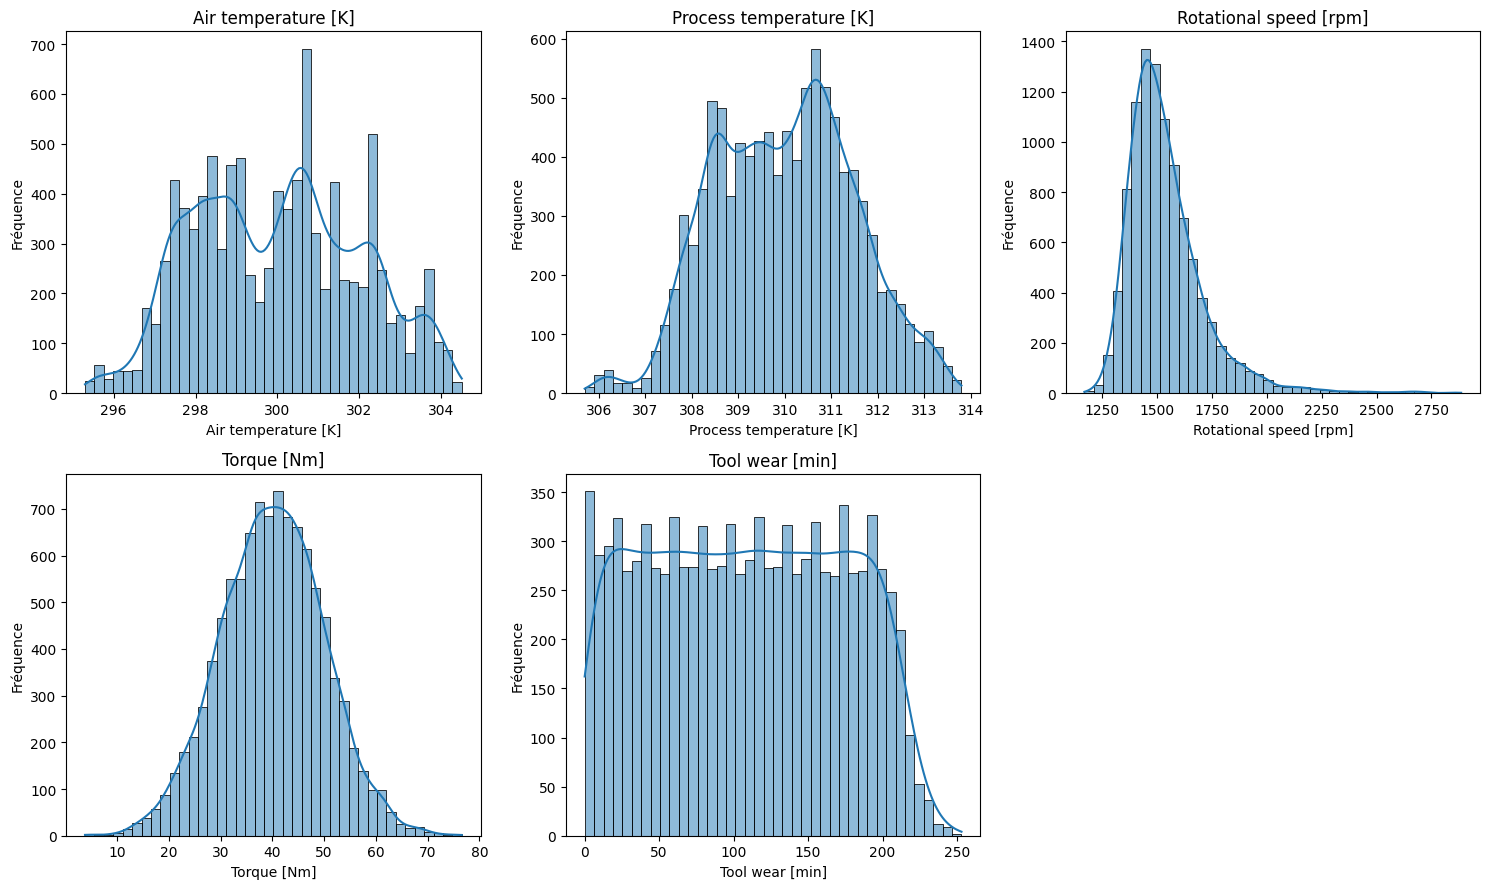

In [ ]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flatten(), numeric_features):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")

fig.delaxes(axes.flatten()[-1])

plt.tight_layout()
plt.show()

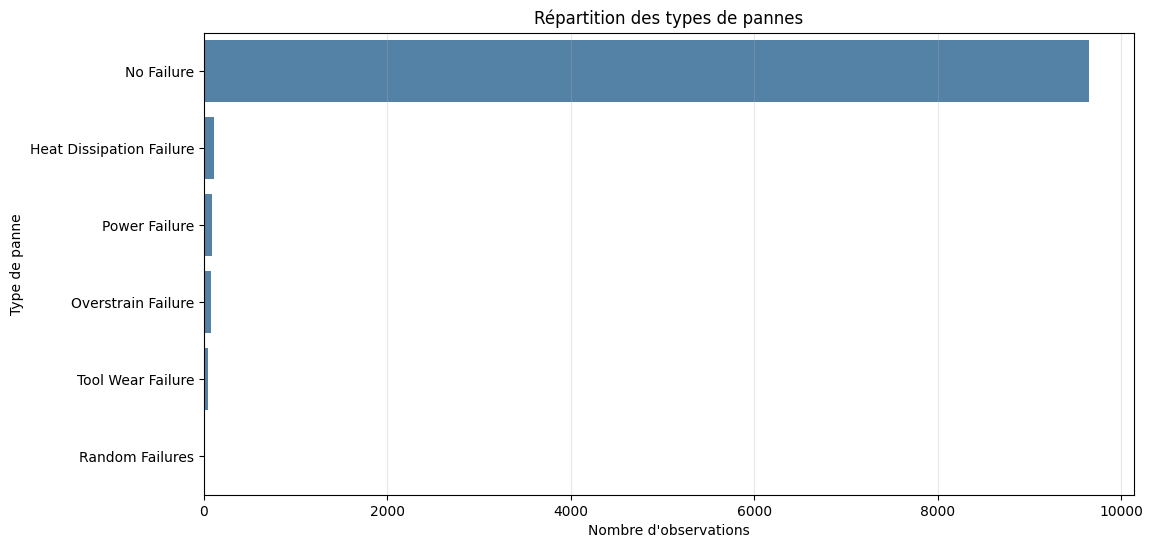

,proportion
Failure Type,
No Failure,96.52
Heat Dissipation Failure,1.12
Power Failure,0.95
Overstrain Failure,0.78
Tool Wear Failure,0.45
Random Failures,0.18


In [ ]:
plt.figure(figsize=(12, 6))

class_counts = df["Failure Type"].value_counts()

sns.barplot(
    x=class_counts.values,
    y=class_counts.index,
    color="steelblue"
)

plt.title("Répartition des types de pannes")
plt.xlabel("Nombre d'observations")
plt.ylabel("Type de panne")
plt.grid(axis="x", alpha=0.3)

plt.show()

class_percent = (
    df["Failure Type"].value_counts(normalize=True) * 100
)

display(class_percent.round(2))


## 4. Analyse des corrélations

Cette étape vise à identifier les relations linéaires
entre les variables numériques du dataset.

Nous utilisons une matrice de corrélation de Pearson
pour examiner les relations entre les températures,
la vitesse de rotation, le couple et l'usure de l'outil.

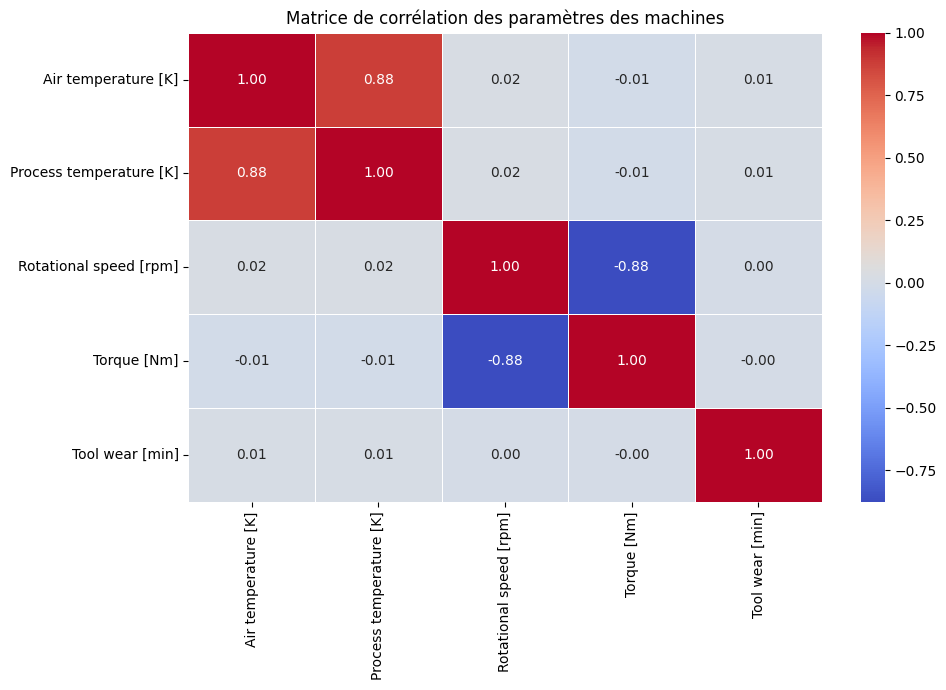

In [ ]:
# Calcul de la matrice de corrélation
corr_matrix = df[numeric_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matrice de corrélation des paramètres des machines")
plt.tight_layout()
plt.show()

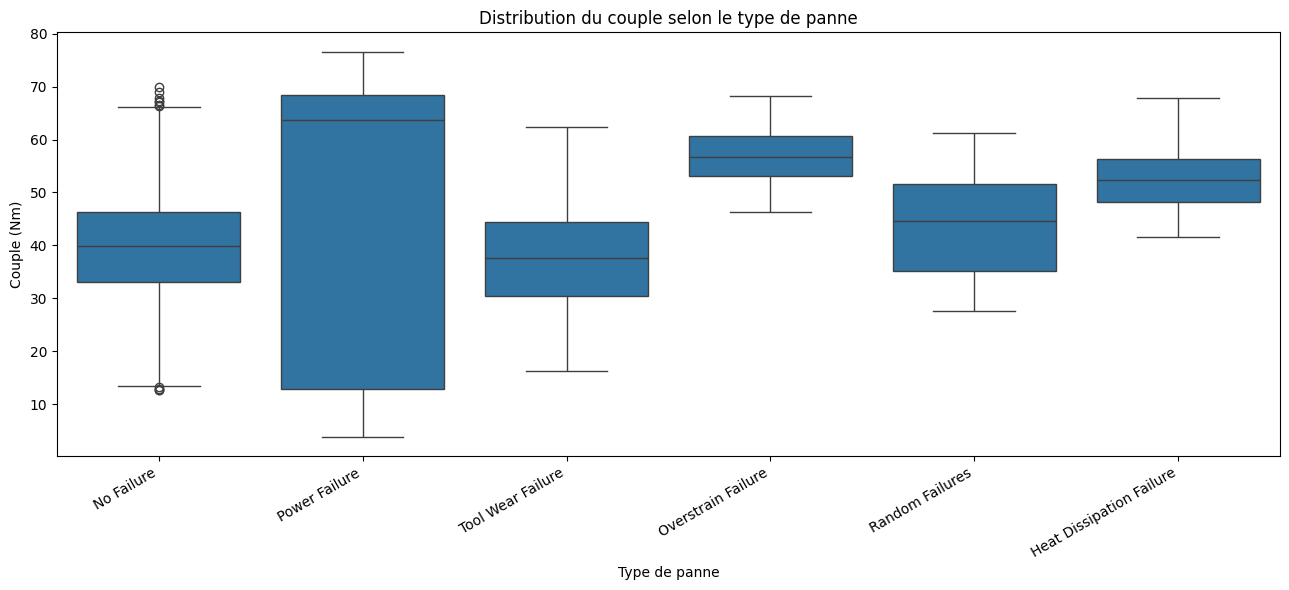

In [ ]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df,
    x="Failure Type",
    y="Torque [Nm]"
)

plt.title("Distribution du couple selon le type de panne")
plt.xlabel("Type de panne")
plt.ylabel("Couple (Nm)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 5. Préparation des données

Nous utilisons les cinq paramètres numériques et la
variable catégorielle Type pour prédire Failure Type.

Les colonnes UDI, Product ID et Target sont exclues
afin de limiter les risques de fuite de données.

Nous séparons les données en Train, Validation et Test
avec une stratification pour conserver les proportions
des six classes dans chaque ensemble.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Définir les variables explicatives
X = df.drop(columns=[
    "UDI",
    "Product ID",
    "Target",
    "Failure Type"
])

# Encoder les 6 classes de la cible
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["Failure Type"])

print("Variables explicatives :")
print(X.columns.tolist())

print("\nCorrespondance des classes :")
for i, classe in enumerate(label_encoder.classes_):
    print(f"{i} : {classe}")

# Séparation 70 % Train, 15 % Validation, 15 % Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDimensions :")
print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Variables explicatives :
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Correspondance des classes :
0 : Heat Dissipation Failure
1 : No Failure
2 : Overstrain Failure
3 : Power Failure
4 : Random Failures
5 : Tool Wear Failure

Dimensions :
Train : (7000, 6) (7000,)
Validation : (1500, 6) (1500,)
Test : (1500, 6) (1500,)


In [ ]:
# Vérifier les proportions dans chaque ensemble
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name} :")
    counts = pd.Series(labels).value_counts().sort_index()

    for i, count in counts.items():
        print(f"{label_encoder.classes_[i]} : {count}")


Train :
Heat Dissipation Failure : 78
No Failure : 6756
Overstrain Failure : 55
Power Failure : 67
Random Failures : 13
Tool Wear Failure : 31

Validation :
Heat Dissipation Failure : 17
No Failure : 1448
Overstrain Failure : 11
Power Failure : 14
Random Failures : 3
Tool Wear Failure : 7

Test :
Heat Dissipation Failure : 17
No Failure : 1448
Overstrain Failure : 12
Power Failure : 14
Random Failures : 2
Tool Wear Failure : 7


## 6. Encodage et standardisation

La variable catégorielle Type est transformée par One-Hot Encoding.

Les cinq variables numériques sont standardisées avec StandardScaler.

Le prétraitement est ajusté uniquement sur l'ensemble Train,
puis appliqué aux ensembles Validation et Test afin d'éviter
les fuites de données.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np

# Variables numériques et catégorielles
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

# Pipeline de preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

# Apprentissage uniquement sur Train
X_train_processed = preprocessor.fit_transform(X_train)

# Application sur Validation et Test
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Conversion en float32 pour PyTorch
X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

print("Train :", X_train_processed.shape)
print("Validation :", X_val_processed.shape)
print("Test :", X_test_processed.shape)

print("\nNoms des variables après transformation :")
print(preprocessor.get_feature_names_out())

print("\nMoyennes des cinq variables numériques (Train) :")
print(X_train_processed[:, :5].mean(axis=0).round(4))

print("\nÉcarts-types des cinq variables numériques (Train) :")
print(X_train_processed[:, :5].std(axis=0).round(4))

Train : (7000, 8)
Validation : (1500, 8)
Test : (1500, 8)

Noms des variables après transformation :
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']

Moyennes des cinq variables numériques (Train) :
[-0. -0. -0. -0.  0.]

Écarts-types des cinq variables numériques (Train) :
[1. 1. 1. 1. 1.]


## 7. Équilibrage des classes avec SMOTENC

Le dataset présente un déséquilibre important entre les six classes.

SMOTENC est utilisé pour générer des observations synthétiques
des classes minoritaires tout en tenant compte de la variable
catégorielle Type.

L'équilibrage est effectué uniquement sur Train.
Les ensembles Validation et Test conservent leur distribution originale.

In [ ]:
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Copie des données Train uniquement
X_train_smote = X_train.copy()

# Standardiser les colonnes numériques
smote_scaler = StandardScaler()

X_train_smote[numeric_features] = smote_scaler.fit_transform(
    X_train_smote[numeric_features]
)

# Encoder temporairement Type en codes entiers
type_categories = sorted(X_train_smote["Type"].unique())
type_mapping = {
    category: i for i, category in enumerate(type_categories)
}

X_train_smote["Type"] = (
    X_train_smote["Type"].map(type_mapping).astype(int)
)

# Identifier la position de la variable catégorielle
categorical_index = [
    X_train_smote.columns.get_loc("Type")
]

# Stratégie d'équilibrage partiel
sampling_strategy = {
    i: 500
    for i, name in enumerate(label_encoder.classes_)
    if name != "No Failure"
}

# SMOTENC
smote_nc = SMOTENC(
    categorical_features=categorical_index,
    sampling_strategy=sampling_strategy,
    random_state=42,
    k_neighbors=3
)

X_resampled, y_train_balanced = smote_nc.fit_resample(
    X_train_smote,
    y_train
)

print("Avant SMOTENC :", X_train.shape)
print("Après SMOTENC :", X_resampled.shape)

print("\nRépartition des classes après SMOTENC :")
for i, count in pd.Series(y_train_balanced).value_counts().sort_index().items():
    print(f"{label_encoder.classes_[i]} : {count}")

Avant SMOTENC : (7000, 6)
Après SMOTENC : (9256, 6)

Répartition des classes après SMOTENC :
Heat Dissipation Failure : 500
No Failure : 6756
Overstrain Failure : 500
Power Failure : 500
Random Failures : 500
Tool Wear Failure : 500


## 8. Préparation des données pour PyTorch

Après l'équilibrage partiel avec SMOTENC, les données
synthétiques sont converties au format numérique attendu
par notre réseau MLP.

Les variables numériques sont standardisées et la variable
catégorielle Type est encodée en One-Hot.

Les paramètres de standardisation restent ceux appris
sur les données d'entraînement originales.

In [ ]:
# Copier les données après SMOTENC
X_balanced_df = X_resampled.copy()

# Restaurer les valeurs numériques originales
X_balanced_df[numeric_features] = smote_scaler.inverse_transform(
    X_balanced_df[numeric_features]
)

# Restaurer les catégories Type
inverse_type_mapping = {
    v: k for k, v in type_mapping.items()
}

X_balanced_df["Type"] = (
    X_balanced_df["Type"]
    .astype(int)
    .map(inverse_type_mapping)
)

# Appliquer le preprocessing déjà entraîné sur Train
X_train_balanced_processed = preprocessor.transform(
    X_balanced_df
).astype(np.float32)

# Convertir les labels
y_train_balanced = np.asarray(
    y_train_balanced,
    dtype=np.int64
)

print("X Train équilibré :", X_train_balanced_processed.shape)
print("y Train équilibré :", y_train_balanced.shape)

print("X Validation :", X_val_processed.shape)
print("X Test :", X_test_processed.shape)

print("\nValeurs manquantes après transformation :",
      np.isnan(X_train_balanced_processed).sum())

print("\nPremières observations :")
display(pd.DataFrame(
    X_train_balanced_processed[:5],
    columns=preprocessor.get_feature_names_out()
))

X Train équilibré : (9256, 8)
y Train équilibré : (9256,)
X Validation : (1500, 8)
X Test : (1500, 8)

Valeurs manquantes après transformation : 0

Premières observations :


,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],cat__Type_H,cat__Type_L,cat__Type_M
0,0.493074,0.807639,-0.974451,0.629893,-0.723430,0.0,1.0,0.0
1,-1.252940,-0.949378,-0.319077,-0.122863,-1.476526,1.0,0.0,0.0
2,0.343416,-0.273602,-0.652318,0.981180,0.892590,0.0,0.0,1.0
3,1.041822,0.064286,0.425160,-1.016133,1.065174,1.0,0.0,0.0
4,-0.704193,0.064286,1.013886,-1.287126,-1.617732,0.0,1.0,0.0


## 9. Classification multiclasses avec PyTorch

Nous construisons un réseau de neurones MLP pour prédire
six catégories de pannes industrielles.

Architecture :
- Entrée : 8 neurones
- Couche cachée 1 : 64 neurones + ReLU
- Couche cachée 2 : 32 neurones + ReLU
- Sortie : 6 neurones

Fonction de perte : CrossEntropyLoss
Optimiseur : Adam

In [ ]:
import torch
import torch.nn as nn
import numpy as np

from torch.utils.data import TensorDataset, DataLoader

# Reproductibilité
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device utilisé :", device)

# Conversion des données Train équilibrées
X_train_tensor = torch.tensor(
    X_train_balanced_processed,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_balanced,
    dtype=torch.long
)

# Validation
X_val_tensor = torch.tensor(
    X_val_processed,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

# Test
X_test_tensor = torch.tensor(
    X_test_processed,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

# Création des datasets
train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Train batches :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches :", len(test_loader))

Device utilisé : cuda
Train batches : 145
Validation batches : 24
Test batches : 24


In [ ]:
class MLPClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(8, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 6)
        )

    def forward(self, x):
        return self.network(x)


# Initialiser le modèle
model = MLPClassifier().to(device)

# Fonction de perte
criterion = nn.CrossEntropyLoss()

# Optimiseur
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Nombre d'époques
epochs = 100

print(model)

print("\nNombre de paramètres :",
      sum(p.numel() for p in model.parameters()))

print("Learning rate :", optimizer.param_groups[0]["lr"])
print("Nombre d'époques :", epochs)

MLPClassifier(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)

Nombre de paramètres : 2854
Learning rate : 0.001
Nombre d'époques : 100


## 10. Entraînement du modèle de classification

Le modèle MLP est entraîné pendant 100 époques à l'aide
de l'optimiseur Adam et de la fonction CrossEntropyLoss.

Nous suivons les métriques suivantes :
- Training Loss et Validation Loss
- Training Accuracy et Validation Accuracy
- Validation F1-score macro

Le modèle est entraîné sur les données partiellement
équilibrées par SMOTENC.

L'ensemble de validation conserve sa distribution originale.

In [ ]:
from sklearn.metrics import f1_score

# Historiques des métriques
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []
val_f1_scores = []

for epoch in range(epochs):

    # ===== PHASE TRAINING =====
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        # Forward propagation
        outputs = model(X_batch)

        # Calcul de la perte
        loss = criterion(outputs, y_batch)

        # Backpropagation
        loss.backward()
        optimizer.step()

        # Accumuler les statistiques
        train_loss_sum += loss.item() * X_batch.size(0)

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (predictions == y_batch).sum().item()
        train_total += y_batch.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # ===== PHASE VALIDATION =====
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    all_val_true = []
    all_val_pred = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            val_loss_sum += loss.item() * X_batch.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == y_batch).sum().item()
            val_total += y_batch.size(0)

            all_val_true.extend(y_batch.cpu().numpy())
            all_val_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    val_f1 = f1_score(
        all_val_true,
        all_val_pred,
        average="macro",
        labels=range(6),
        zero_division=0
    )

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    val_f1_scores.append(val_f1)

    # Affichage toutes les 10 époques
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1 Macro: {val_f1:.4f}"
        )

print("\nEntraînement terminé !")

Epoch [10/100] | Train Loss: 0.2032 | Val Loss: 0.1660 | Train Acc: 0.9211 | Val Acc: 0.9460 | Val F1 Macro: 0.4799
Epoch [20/100] | Train Loss: 0.1428 | Val Loss: 0.1547 | Train Acc: 0.9488 | Val Acc: 0.9500 | Val F1 Macro: 0.4878
Epoch [30/100] | Train Loss: 0.1105 | Val Loss: 0.1602 | Train Acc: 0.9612 | Val Acc: 0.9500 | Val F1 Macro: 0.5069
Epoch [40/100] | Train Loss: 0.0887 | Val Loss: 0.1685 | Train Acc: 0.9716 | Val Acc: 0.9500 | Val F1 Macro: 0.5140
Epoch [50/100] | Train Loss: 0.0767 | Val Loss: 0.1651 | Train Acc: 0.9749 | Val Acc: 0.9600 | Val F1 Macro: 0.5234
Epoch [60/100] | Train Loss: 0.0688 | Val Loss: 0.1770 | Train Acc: 0.9773 | Val Acc: 0.9520 | Val F1 Macro: 0.5187
Epoch [70/100] | Train Loss: 0.0606 | Val Loss: 0.1818 | Train Acc: 0.9808 | Val Acc: 0.9567 | Val F1 Macro: 0.5277
Epoch [80/100] | Train Loss: 0.0548 | Val Loss: 0.1906 | Train Acc: 0.9825 | Val Acc: 0.9580 | Val F1 Macro: 0.5194
Epoch [90/100] | Train Loss: 0.0497 | Val Loss: 0.1974 | Train Acc: 0.98

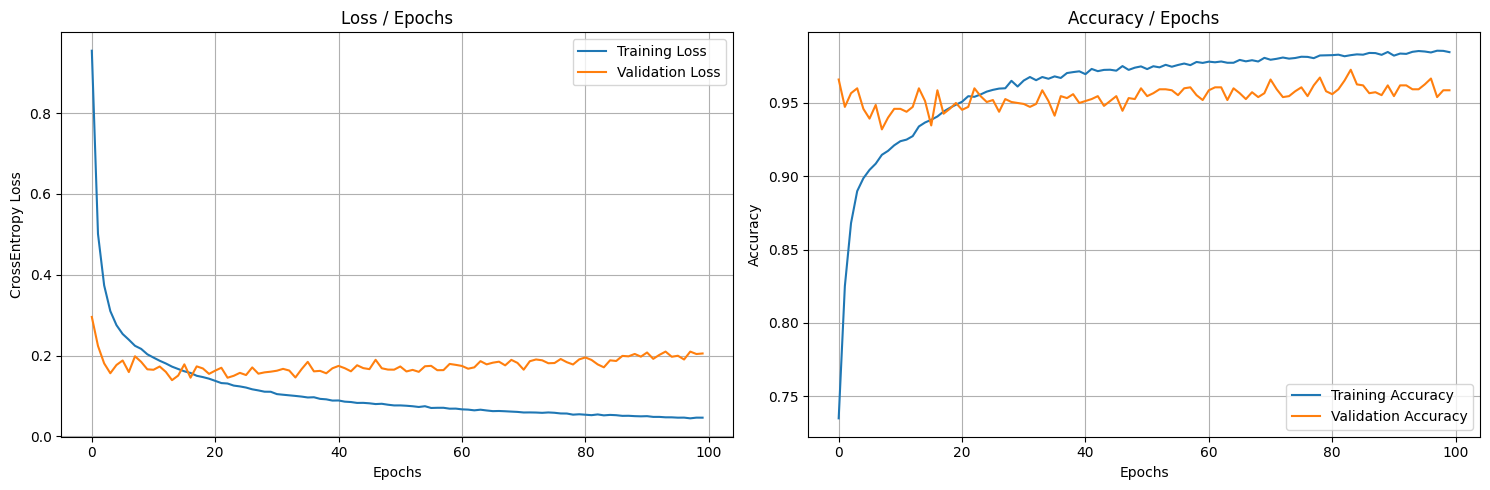

Dernière Validation Accuracy : 0.9587
Dernier Validation F1 Macro : 0.5318
Meilleure époque selon F1 Macro : 97
Meilleur F1 Macro Validation : 0.5475


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss / Epochs
axes[0].plot(train_losses, label="Training Loss")
axes[0].plot(val_losses, label="Validation Loss")

axes[0].set_title("Loss / Epochs")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy / Epochs
axes[1].plot(train_accuracies, label="Training Accuracy")
axes[1].plot(val_accuracies, label="Validation Accuracy")

axes[1].set_title("Accuracy / Epochs")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Dernière Validation Accuracy :", round(val_accuracies[-1], 4))
print("Dernier Validation F1 Macro :", round(val_f1_scores[-1], 4))

best_f1_epoch = np.argmax(val_f1_scores) + 1

print("Meilleure époque selon F1 Macro :", best_f1_epoch)
print("Meilleur F1 Macro Validation :", round(max(val_f1_scores), 4))

## 11. Évaluation du modèle de classification

Nous évaluons le modèle MLP sur les données d'entraînement
et de validation à l'aide des métriques suivantes :

- Accuracy
- Precision macro
- Recall macro (sensibilité)
- F1-score macro
- F1-score weighted
- Matrice de confusion

Le F1-score macro permet de mieux évaluer les performances
sur les classes minoritaires.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Fonction de prédiction
def predict_classes(model, X_tensor):
    model.eval()

    with torch.no_grad():
        outputs = model(X_tensor.to(device))
        predictions = torch.argmax(outputs, dim=1)

    return predictions.cpu().numpy()


# Prédictions Train et Validation
y_pred_train = predict_classes(model, X_train_tensor)
y_pred_val = predict_classes(model, X_val_tensor)


# Fonction pour calculer les métriques
def evaluate_classifier(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 Weighted": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }


# Tableau comparatif
metrics_comparison = pd.DataFrame({
    "MLP Train (SMOTENC)": evaluate_classifier(
        y_train_balanced, y_pred_train
    ),
    "MLP Validation": evaluate_classifier(
        y_val, y_pred_val
    )
}).T

display(metrics_comparison.round(4))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
MLP Train (SMOTENC),0.9858,0.9646,0.9884,0.9762,0.9860
MLP Validation,0.9587,0.5012,0.5812,0.5318,0.9657


In [ ]:
print("Rapport de classification - Validation\n")

print(
    classification_report(
        y_val,
        y_pred_val,
        labels=np.arange(6),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

Rapport de classification - Validation

                          precision    recall  f1-score   support

Heat Dissipation Failure     0.5833    0.8235    0.6829        17
              No Failure     0.9894    0.9689    0.9791      1448
      Overstrain Failure     0.5882    0.9091    0.7143        11
           Power Failure     0.8462    0.7857    0.8148        14
         Random Failures     0.0000    0.0000    0.0000         3
       Tool Wear Failure     0.0000    0.0000    0.0000         7

                accuracy                         0.9587      1500
               macro avg     0.5012    0.5812    0.5318      1500
            weighted avg     0.9739    0.9587    0.9657      1500



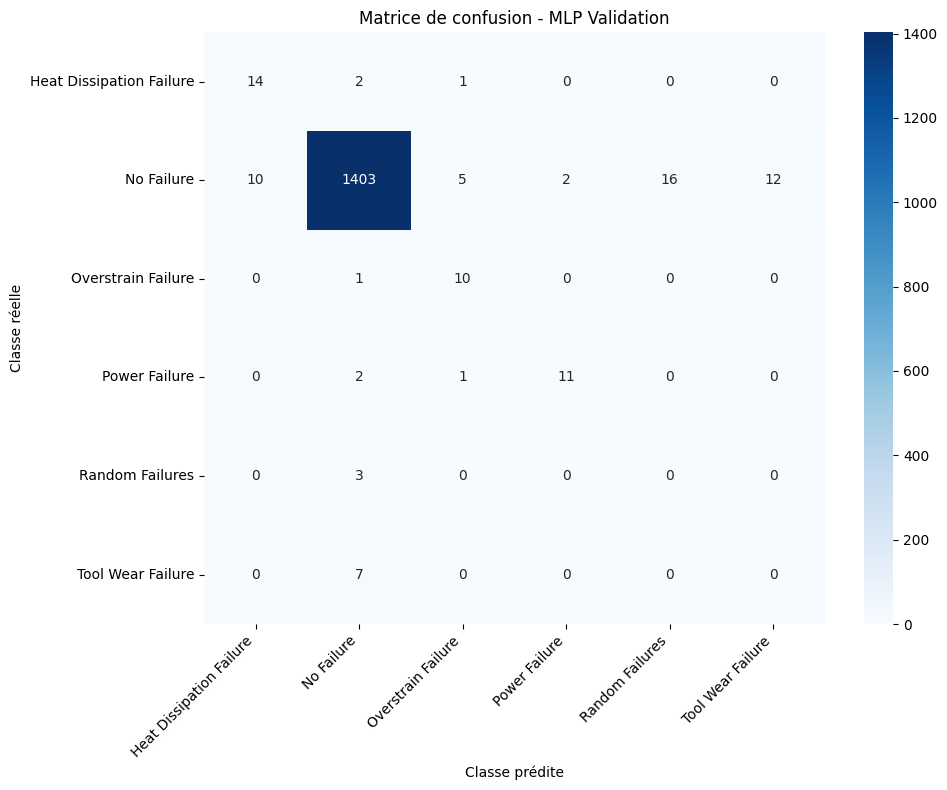

In [ ]:
cm = confusion_matrix(
    y_val,
    y_pred_val,
    labels=np.arange(6)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Matrice de confusion - MLP Validation")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Optimisation des hyperparamètres avec GridSearchCV

GridSearchCV sera utilisé pour rechercher les meilleurs
hyperparamètres du réseau MLP :

- Learning rate
- Optimiseur
- Architecture
- Nombre d'époques

Le F1-score macro sera utilisé comme métrique principale.

Pour éviter les fuites de données, le preprocessing et
l'équilibrage seront réalisés indépendamment dans chaque
fold d'entraînement.

In [ ]:
%pip install -q skorch imbalanced-learn

import sklearn
import imblearn
import skorch

print("scikit-learn :", sklearn.__version__)
print("imbalanced-learn :", imblearn.__version__)
print("skorch :", skorch.__version__)

print("\nDimensions du Train original :", X_train.shape)
print("Dimensions du Train équilibré :", X_train_balanced_processed.shape)
print("Nombre de classes :", len(label_encoder.classes_))

scikit-learn : 1.6.1
imbalanced-learn : 0.14.2
skorch : 1.4.0

Dimensions du Train original : (7000, 6)
Dimensions du Train équilibré : (9256, 8)
Nombre de classes : 6


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder,
    OneHotEncoder
)
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from skorch import NeuralNetClassifier

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# Étape A : standardiser les variables numériques
# et encoder temporairement Type en entier
pre_smote = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OrdinalEncoder(), ["Type"])
])

# Étape B : SMOTENC
# Les 5 premières colonnes sont numériques.
# La colonne d'indice 5 correspond à Type.
smote_grid = SMOTENC(
    categorical_features=[5],
    sampling_strategy={
        0: 500,
        2: 500,
        3: 500,
        4: 500,
        5: 500
    },
    random_state=42,
    k_neighbors=3
)

# Étape C : One-Hot Encoding après SMOTENC
post_smote = ColumnTransformer([
    ("num", "passthrough", [0, 1, 2, 3, 4]),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), [5])
])

print("Pipeline de preprocessing configuré !")

Pipeline de preprocessing configuré !


In [ ]:
class TunableMLPClassifier(nn.Module):

    def __init__(self, hidden1=64, hidden2=32):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(8, hidden1),
            nn.ReLU(),

            nn.Linear(hidden1, hidden2),
            nn.ReLU(),

            nn.Linear(hidden2, 6)
        )

    def forward(self, x):
        return self.network(x)


# Vérification
test_model = TunableMLPClassifier(
    hidden1=128,
    hidden2=64
)

print(test_model)

TunableMLPClassifier(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [ ]:
# Modèle PyTorch compatible scikit-learn
net = NeuralNetClassifier(
    module=TunableMLPClassifier,
    criterion=nn.CrossEntropyLoss,
    optimizer=optim.Adam,
    lr=0.001,
    max_epochs=30,
    batch_size=64,
    train_split=None,
    iterator_train__shuffle=True,
    verbose=0,
    device=device
)

# Pipeline complet
pipeline_grid = Pipeline([
    ("pre_smote", pre_smote),
    ("smote", smote_grid),
    ("post_smote", post_smote),
    ("net", net)
])

print("Pipeline GridSearchCV prêt !")

print("\nÉtapes :")
for name, step in pipeline_grid.steps:
    print(name, ":", type(step).__name__)

Pipeline GridSearchCV prêt !

Étapes :
pre_smote : ColumnTransformer
smote : SMOTENC
post_smote : ColumnTransformer
net : NeuralNetClassifier


In [ ]:
from sklearn.preprocessing import FunctionTransformer

# Conversion en float32 pour PyTorch
to_float32 = FunctionTransformer(
    lambda X: np.asarray(X, dtype=np.float32)
)

# Insérer la conversion avant le réseau
pipeline_grid.steps.insert(
    -1,
    ("float32", to_float32)
)

print("Étapes du pipeline :")
print([name for name, _ in pipeline_grid.steps])

Étapes du pipeline :
['pre_smote', 'smote', 'post_smote', 'float32', 'net']


In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [28]:
param_grid = [
    {
        "net__module__hidden1": [64],
        "net__module__hidden2": [32],
        "net__lr": [0.001, 0.0005],
        "net__optimizer": [optim.Adam, optim.SGD],
        "net__max_epochs": [30, 60]
    },
    {
        "net__module__hidden1": [128],
        "net__module__hidden2": [64],
        "net__lr": [0.001, 0.0005],
        "net__optimizer": [optim.Adam, optim.SGD],
        "net__max_epochs": [30, 60]
    }
]

In [29]:
grid_search = GridSearchCV(
    estimator=pipeline_grid,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    verbose=2,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

print("\nMeilleurs hyperparamètres :")
print(grid_search.best_params_)

print("\nMeilleur F1 Macro CV :")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   7.5s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   7.6s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   7.6s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.sgd.SGD'>; total time=   6.7s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.sgd.SGD'>; total time=   6.6s
[CV] END net__lr=0.001, net__max_epochs=30, net__module__hidden1=64, net__module__hidden2=32, net__optimizer=<class 'torch.optim.sgd.SGD'>

## 13. Évaluation du modèle optimisé

Après la recherche des hyperparamètres avec GridSearchCV,
nous évaluons le meilleur modèle sur l'ensemble de validation.

Nous comparons trois approches :
- Le MLP initial
- Le MLP optimisé
- Un classificateur majoritaire prédisant toujours No Failure

La métrique principale est le F1-score macro,
car les classes de pannes sont fortement déséquilibrées.

In [30]:
# Récupérer le meilleur pipeline
best_model = grid_search.best_estimator_

# Prédictions sur Validation
y_pred_val_optimized = best_model.predict(X_val)

# Baseline majoritaire : toujours No Failure
no_failure_id = label_encoder.transform(["No Failure"])[0]

y_pred_majority = np.full(
    len(y_val),
    no_failure_id,
    dtype=np.int64
)

# Comparer les modèles
comparison_val = pd.DataFrame({
    "MLP Initial": evaluate_classifier(
        y_val, y_pred_val
    ),
    "MLP Optimisé": evaluate_classifier(
        y_val, y_pred_val_optimized
    ),
    "Modèle Majoritaire": evaluate_classifier(
        y_val, y_pred_majority
    )
}).T

display(comparison_val.round(4))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
MLP Initial,0.9587,0.5012,0.5812,0.5318,0.9657
MLP Optimisé,0.9640,0.5379,0.5994,0.5565,0.9693
Modèle Majoritaire,0.9653,0.1609,0.1667,0.1637,0.9483


In [31]:
print("Rapport de classification - MLP optimisé\n")

print(
    classification_report(
        y_val,
        y_pred_val_optimized,
        labels=np.arange(6),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

Rapport de classification - MLP optimisé

                          precision    recall  f1-score   support

Heat Dissipation Failure     0.6190    0.7647    0.6842        17
              No Failure     0.9895    0.9744    0.9819      1448
      Overstrain Failure     0.6471    1.0000    0.7857        11
           Power Failure     0.9091    0.7143    0.8000        14
         Random Failures     0.0000    0.0000    0.0000         3
       Tool Wear Failure     0.0625    0.1429    0.0870         7

                accuracy                         0.9640      1500
               macro avg     0.5379    0.5994    0.5565      1500
            weighted avg     0.9757    0.9640    0.9693      1500



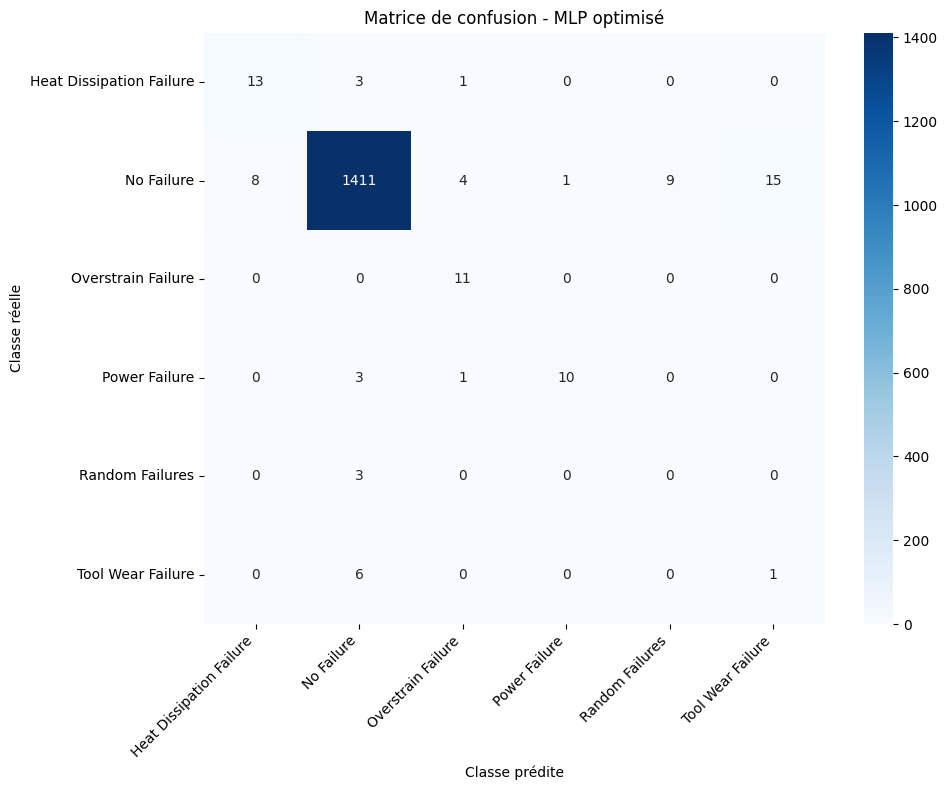

In [32]:
cm_optimized = confusion_matrix(
    y_val,
    y_pred_val_optimized,
    labels=np.arange(6)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_optimized,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Matrice de confusion - MLP optimisé")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 14. Régularisation du modèle MLP

Nous appliquons plusieurs techniques de régularisation
au modèle sélectionné par GridSearchCV :

- Dropout : désactivation aléatoire de neurones.
- Weight Decay : pénalisation des poids du réseau.
- Early Stopping : arrêt de l'entraînement lorsque la
  performance sur Validation ne s'améliore plus.

L'objectif est de réduire le surapprentissage et
d'améliorer la généralisation, notamment pour les
classes minoritaires.

In [33]:
import torch
import torch.nn as nn

class RegularizedMLPClassifier(nn.Module):

    def __init__(self, dropout_rate=0.2):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(8, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(64, 6)
        )

    def forward(self, x):
        return self.network(x)


# Reproductibilité
torch.manual_seed(42)

# Initialisation du modèle régularisé
regularized_model = RegularizedMLPClassifier(
    dropout_rate=0.2
).to(device)

# Fonction de perte
criterion_reg = nn.CrossEntropyLoss()

# Optimiseur avec Weight Decay
optimizer_reg = torch.optim.Adam(
    regularized_model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

print(regularized_model)

print("\nNombre de paramètres :", sum(
    p.numel() for p in regularized_model.parameters()
))

print("Learning rate :", optimizer_reg.param_groups[0]["lr"])
print("Weight decay :", optimizer_reg.param_groups[0]["weight_decay"])

RegularizedMLPClassifier(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=6, bias=True)
  )
)

Nombre de paramètres : 9798
Learning rate : 0.0005
Weight decay : 0.0001


### 14.2 Entraînement avec Early Stopping

Le MLP régularisé utilise Dropout, Weight Decay et Early Stopping.

Le modèle est entraîné pendant un maximum de 150 époques.
Les performances sont suivies sur Train et Validation.

Le F1-score macro de Validation permet de sélectionner les
meilleurs poids afin de privilégier la reconnaissance des
différentes classes, y compris les classes minoritaires.

In [34]:
import copy
from sklearn.metrics import f1_score

max_epochs_reg = 150
patience = 15
min_delta = 0.001

train_losses_reg = []
val_losses_reg = []
train_acc_reg = []
val_acc_reg = []
val_f1_reg = []

best_f1 = -1.0
best_epoch_reg = 0
best_weights_reg = None
patience_counter = 0

for epoch in range(max_epochs_reg):

    # ===== ENTRAÎNEMENT =====
    regularized_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_reg.zero_grad()

        outputs = regularized_model(X_batch)
        loss = criterion_reg(outputs, y_batch)

        loss.backward()
        optimizer_reg.step()

        running_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(1) == y_batch).sum().item()
        total += y_batch.size(0)

    train_losses_reg.append(running_loss / total)
    train_acc_reg.append(correct / total)

    # ===== VALIDATION =====
    regularized_model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_true = []
    all_pred = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = regularized_model(X_batch)
            loss = criterion_reg(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            running_loss += loss.item() * X_batch.size(0)
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

            all_true.extend(y_batch.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())

    val_loss = running_loss / total
    val_accuracy = correct / total

    f1_macro = f1_score(
        all_true,
        all_pred,
        average="macro",
        labels=np.arange(6),
        zero_division=0
    )

    val_losses_reg.append(val_loss)
    val_acc_reg.append(val_accuracy)
    val_f1_reg.append(f1_macro)

    # ===== EARLY STOPPING =====
    if f1_macro > best_f1 + min_delta:
        best_f1 = f1_macro
        best_epoch_reg = epoch + 1
        best_weights_reg = copy.deepcopy(
            regularized_model.state_dict()
        )
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{max_epochs_reg} | "
            f"Train Loss: {train_losses_reg[-1]:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f} | "
            f"Val F1 Macro: {f1_macro:.4f}"
        )

    if patience_counter >= patience:
        print(f"\nEarly Stopping à l'époque {epoch+1}")
        break

# Restaurer les meilleurs poids
regularized_model.load_state_dict(best_weights_reg)
regularized_model.eval()

print("\nMeilleure époque :", best_epoch_reg)
print("Meilleur F1 Macro Validation :", round(best_f1, 4))
print("Nombre d'époques exécutées :", len(val_f1_reg))

Epoch 10/150 | Train Loss: 0.2899 | Val Loss: 0.1699 | Val Accuracy: 0.9453 | Val F1 Macro: 0.4687
Epoch 20/150 | Train Loss: 0.2249 | Val Loss: 0.1691 | Val Accuracy: 0.9447 | Val F1 Macro: 0.4675
Epoch 30/150 | Train Loss: 0.1812 | Val Loss: 0.1570 | Val Accuracy: 0.9480 | Val F1 Macro: 0.4898
Epoch 40/150 | Train Loss: 0.1581 | Val Loss: 0.1480 | Val Accuracy: 0.9527 | Val F1 Macro: 0.4941
Epoch 50/150 | Train Loss: 0.1358 | Val Loss: 0.1529 | Val Accuracy: 0.9507 | Val F1 Macro: 0.4985
Epoch 60/150 | Train Loss: 0.1266 | Val Loss: 0.1621 | Val Accuracy: 0.9507 | Val F1 Macro: 0.5050

Early Stopping à l'époque 62

Meilleure époque : 47
Meilleur F1 Macro Validation : 0.5093
Nombre d'époques exécutées : 62


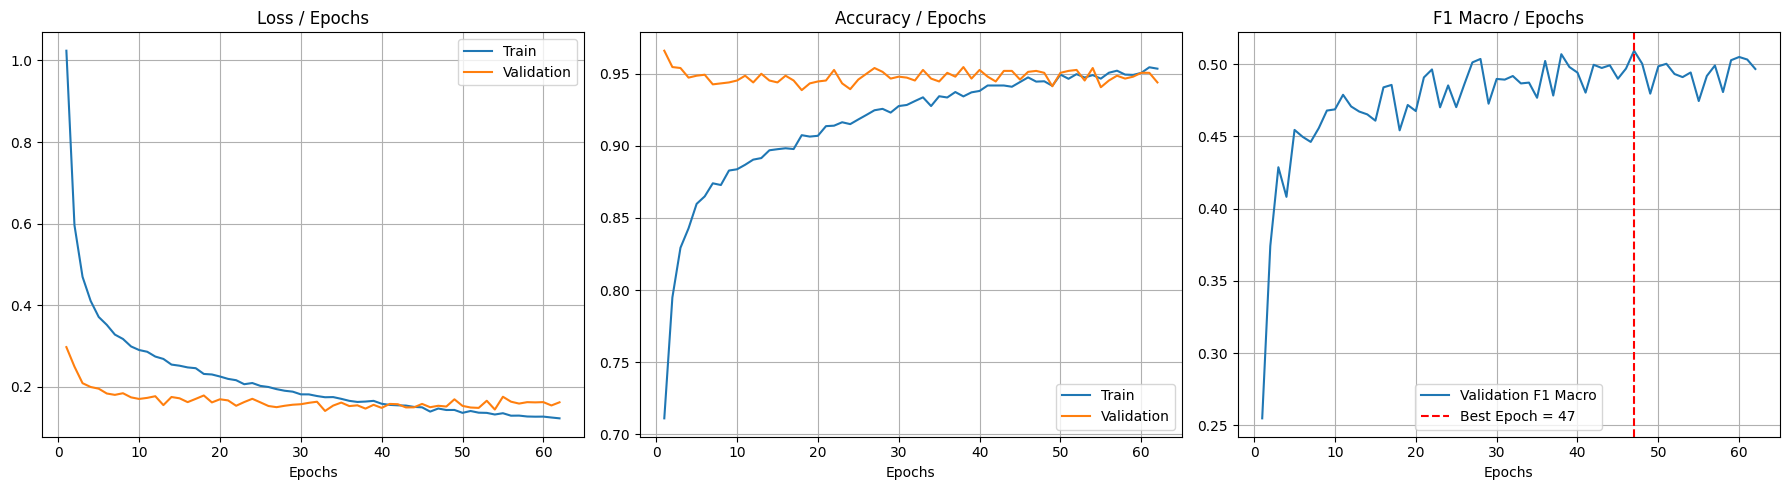

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epoch_range = range(1, len(train_losses_reg) + 1)

# Loss
axes[0].plot(epoch_range, train_losses_reg, label="Train")
axes[0].plot(epoch_range, val_losses_reg, label="Validation")
axes[0].set_title("Loss / Epochs")
axes[0].set_xlabel("Epochs")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epoch_range, train_acc_reg, label="Train")
axes[1].plot(epoch_range, val_acc_reg, label="Validation")
axes[1].set_title("Accuracy / Epochs")
axes[1].set_xlabel("Epochs")
axes[1].legend()
axes[1].grid(True)

# F1 Macro
axes[2].plot(epoch_range, val_f1_reg, label="Validation F1 Macro")
axes[2].axvline(
    best_epoch_reg,
    color="red",
    linestyle="--",
    label=f"Best Epoch = {best_epoch_reg}"
)
axes[2].set_title("F1 Macro / Epochs")
axes[2].set_xlabel("Epochs")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

## 15. Comparaison des modèles sur Validation

Nous comparons les performances des trois modèles :
- MLP initial
- MLP optimisé avec GridSearchCV
- MLP régularisé avec Dropout, Weight Decay et Early Stopping

La comparaison repose principalement sur le F1-score macro,
le recall macro et les résultats par classe.

In [36]:
# Prédictions du modèle régularisé
y_pred_val_reg = predict_classes(
    regularized_model,
    X_val_tensor
)

# Comparaison sur Validation
comparison_reg = pd.DataFrame({
    "MLP Initial": evaluate_classifier(
        y_val, y_pred_val
    ),
    "MLP Optimisé": evaluate_classifier(
        y_val, y_pred_val_optimized
    ),
    "MLP Régularisé": evaluate_classifier(
        y_val, y_pred_val_reg
    ),
    "Modèle Majoritaire": evaluate_classifier(
        y_val, y_pred_majority
    )
}).T

display(comparison_reg.round(4))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
MLP Initial,0.9587,0.5012,0.5812,0.5318,0.9657
MLP Optimisé,0.9640,0.5379,0.5994,0.5565,0.9693
MLP Régularisé,0.9520,0.4647,0.5854,0.5093,0.9610
Modèle Majoritaire,0.9653,0.1609,0.1667,0.1637,0.9483


In [37]:
print("Rapport de classification - MLP régularisé\n")

print(
    classification_report(
        y_val,
        y_pred_val_reg,
        labels=np.arange(6),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

Rapport de classification - MLP régularisé

                          precision    recall  f1-score   support

Heat Dissipation Failure     0.5417    0.7647    0.6341        17
              No Failure     0.9893    0.9620    0.9755      1448
      Overstrain Failure     0.5238    1.0000    0.6875        11
           Power Failure     0.7333    0.7857    0.7586        14
         Random Failures     0.0000    0.0000    0.0000         3
       Tool Wear Failure     0.0000    0.0000    0.0000         7

                accuracy                         0.9520      1500
               macro avg     0.4647    0.5854    0.5093      1500
            weighted avg     0.9719    0.9520    0.9610      1500



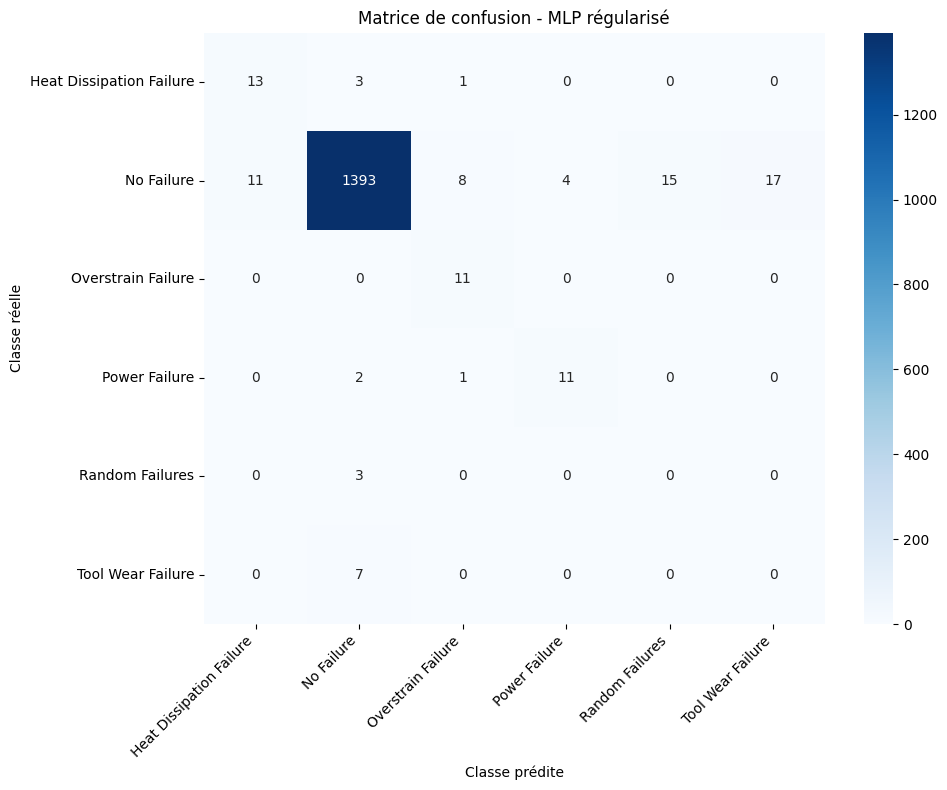

In [38]:
cm_reg = confusion_matrix(
    y_val,
    y_pred_val_reg,
    labels=np.arange(6)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_reg,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Matrice de confusion - MLP régularisé")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. Évaluation finale sur Test

Les modèles sont évalués sur les données de test qui
n'ont pas été utilisées pendant l'entraînement ou
la sélection des hyperparamètres.

Nous comparons le MLP initial, le MLP optimisé,
le MLP régularisé et le modèle majoritaire.

Les métriques utilisées sont l'accuracy, la précision macro,
le recall macro, le F1-score macro et le F1-score pondéré.

In [39]:
# Prédictions MLP initial
y_pred_test_initial = predict_classes(
    model,
    X_test_tensor
)

# Prédictions MLP optimisé
y_pred_test_optimized = best_model.predict(X_test)

# Prédictions MLP régularisé
y_pred_test_reg = predict_classes(
    regularized_model,
    X_test_tensor
)

# Modèle majoritaire
y_pred_test_majority = np.full(
    len(y_test),
    no_failure_id,
    dtype=np.int64
)

# Tableau comparatif sur Test
comparison_test = pd.DataFrame({
    "MLP Initial": evaluate_classifier(
        y_test, y_pred_test_initial
    ),
    "MLP Optimisé": evaluate_classifier(
        y_test, y_pred_test_optimized
    ),
    "MLP Régularisé": evaluate_classifier(
        y_test, y_pred_test_reg
    ),
    "Modèle Majoritaire": evaluate_classifier(
        y_test, y_pred_test_majority
    )
}).T

display(comparison_test.round(4))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
MLP Initial,0.9687,0.5720,0.6270,0.5924,0.9745
MLP Optimisé,0.9673,0.5696,0.6408,0.5968,0.9737
MLP Régularisé,0.9553,0.5322,0.6406,0.5778,0.9664
Modèle Majoritaire,0.9653,0.1609,0.1667,0.1637,0.9483


In [40]:
print("Rapport final - MLP optimisé sur Test\n")

print(
    classification_report(
        y_test,
        y_pred_test_optimized,
        labels=np.arange(6),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

Rapport final - MLP optimisé sur Test

                          precision    recall  f1-score   support

Heat Dissipation Failure     0.6000    0.8824    0.7143        17
              No Failure     0.9930    0.9744    0.9836      1448
      Overstrain Failure     0.8462    0.9167    0.8800        12
           Power Failure     0.9286    0.9286    0.9286        14
         Random Failures     0.0000    0.0000    0.0000         2
       Tool Wear Failure     0.0500    0.1429    0.0741         7

                accuracy                         0.9673      1500
               macro avg     0.5696    0.6408    0.5968      1500
            weighted avg     0.9810    0.9673    0.9737      1500



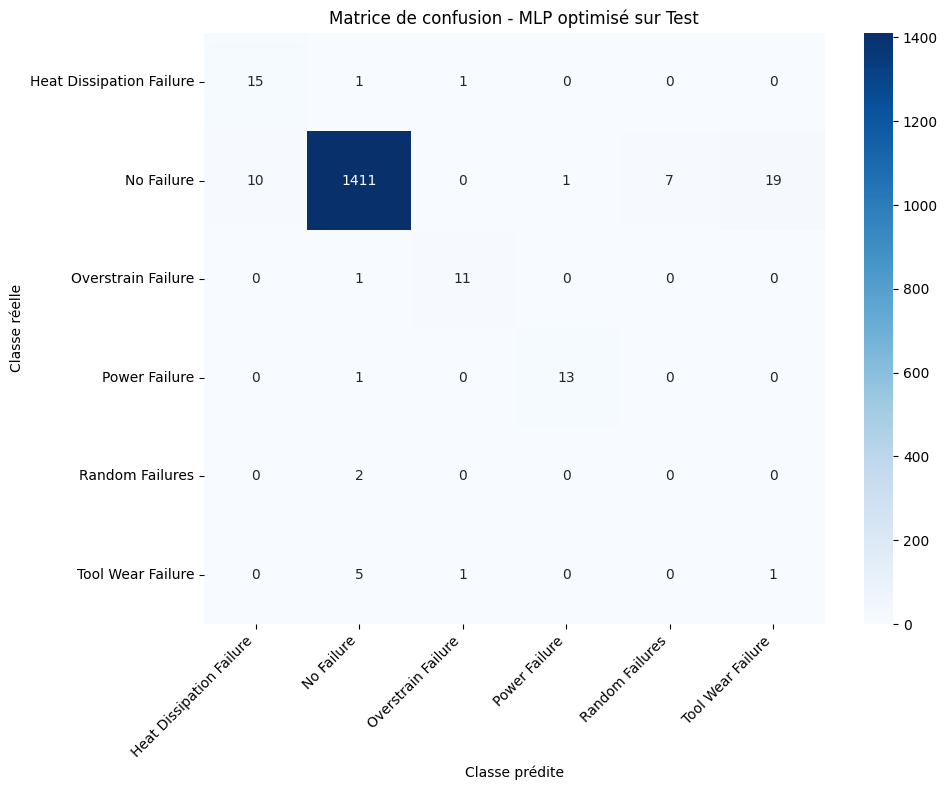

In [41]:
cm_test = confusion_matrix(
    y_test,
    y_pred_test_optimized,
    labels=np.arange(6)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Matrice de confusion - MLP optimisé sur Test")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()